In [376]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw" / "sales_data.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "sales_data.csv"

df = pd.read_csv(DATA_PATH)

df["Date"] = pd.to_datetime(df["Date"])

print(df.head())
print(df.shape)
print(df.info())

        Date Store ID Product ID     Category Region  Inventory Level  \
0 2022-01-01     S001      P0001  Electronics  North              195   
1 2022-01-01     S001      P0002     Clothing  North              117   
2 2022-01-01     S001      P0003     Clothing  North              247   
3 2022-01-01     S001      P0004  Electronics  North              139   
4 2022-01-01     S001      P0005    Groceries  North              152   

   Units Sold  Units Ordered  Price  Discount Weather Condition  Promotion  \
0         102            252  72.72         5             Snowy          0   
1         117            249  80.16        15             Snowy          1   
2         114            612  62.94        10             Snowy          1   
3          45            102  87.63        10             Snowy          0   
4          65            271  54.41         0             Snowy          0   

   Competitor Pricing Seasonality  Epidemic  Demand  
0               85.73      Winter     

In [ ]:
print("Missing values")
print(df.isnull().sum())
print("duplicate rows:",
df.duplicated().sum())
print("Data types:")
print(df.dtypes)

Missing values
<bound method DataFrame.sum of         Date  Store ID  Product ID  Category  Region  Inventory Level  \
0      False     False       False     False   False            False   
1      False     False       False     False   False            False   
2      False     False       False     False   False            False   
3      False     False       False     False   False            False   
4      False     False       False     False   False            False   
...      ...       ...         ...       ...     ...              ...   
75995  False     False       False     False   False            False   
75996  False     False       False     False   False            False   
75997  False     False       False     False   False            False   
75998  False     False       False     False   False            False   
75999  False     False       False     False   False            False   

       Units Sold  Units Ordered  Price  Discount  Weather Condition  \
0    

count    76000.000000
mean       104.317158
std         46.964801
min          4.000000
25%         71.000000
50%        100.000000
75%        133.000000
max        430.000000
Name: Demand, dtype: float64


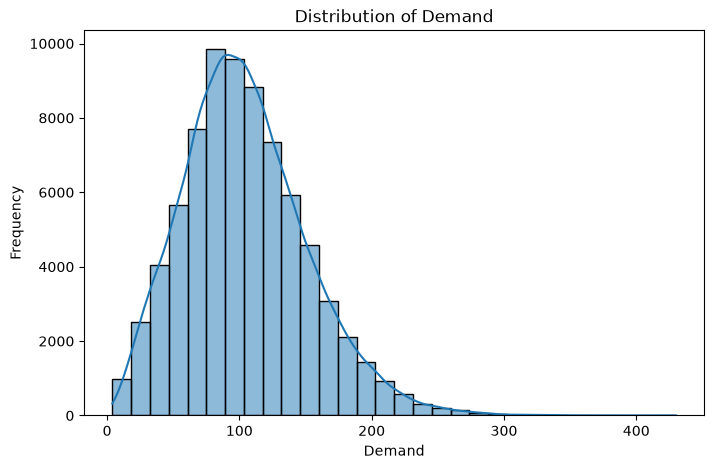

In [378]:
print(df["Demand"].describe())

plt.figure(figsize=(8, 5))
sns.histplot(df["Demand"], bins=30, kde=True)

plt.title("Distribution of Demand")
plt.xlabel("Demand")
plt.ylabel("Frequency")
plt.show()

Category
Groceries      120.976447
Clothing       112.619737
Electronics     97.482018
Toys            92.606955
Furniture       73.581140
Name: Demand, dtype: float64


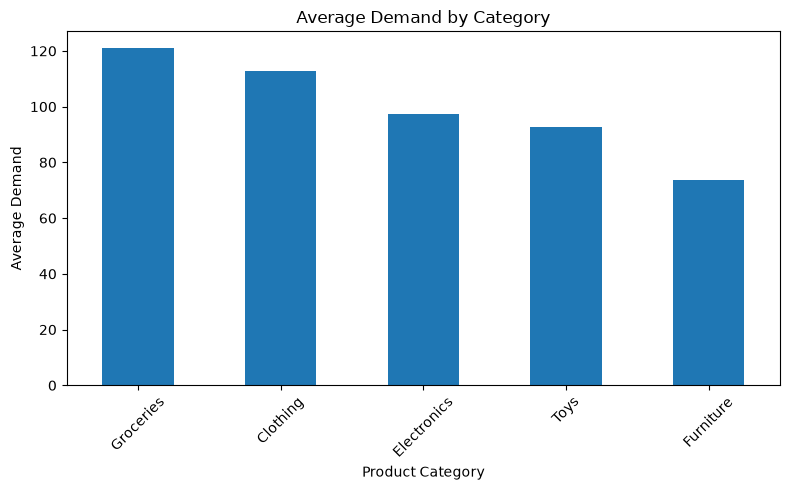

In [379]:
category_demand = (df.groupby("Category")["Demand"].mean().sort_values(ascending=False))

print(category_demand)

category_demand.plot(
      kind="bar",
      figsize=(8, 5)
      )

plt.title("Average Demand by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

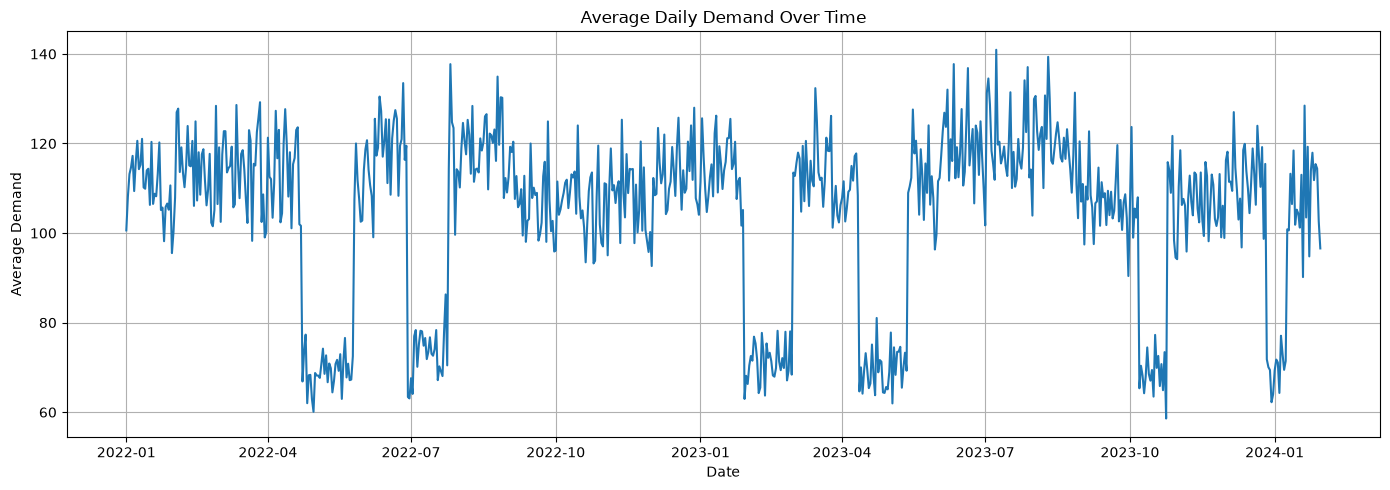

In [380]:

daily_demand = (
    df.groupby("Date")["Demand"]
      .mean()
      .sort_index()
)

plt.figure(figsize=(14, 5))
plt.plot(daily_demand.index, daily_demand.values)

plt.title("Average Daily Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Average Demand")
plt.grid(True)
plt.tight_layout()
plt.show()

Promotion
0     95.026843
1    123.269400
Name: Demand, dtype: float64


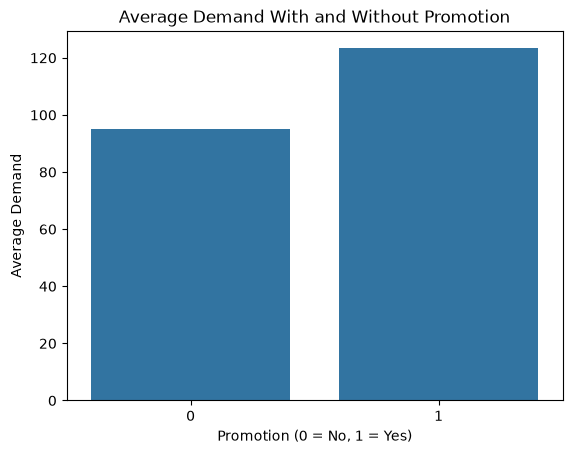

In [381]:
promotion_demand = df.groupby("Promotion")["Demand"].mean()

print(promotion_demand)

sns.barplot(
    data=df,
    x="Promotion",
    y="Demand",
    errorbar=None
)

plt.title("Average Demand With and Without Promotion")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Demand")
plt.show()

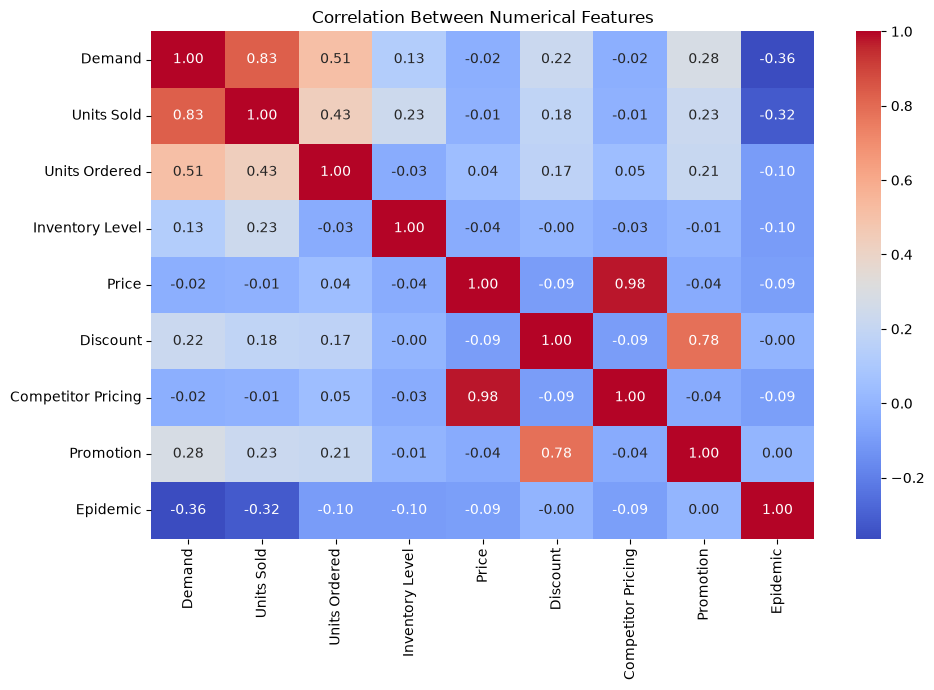

In [382]:
numeric_columns = [
    "Demand",
    "Units Sold",
    "Units Ordered",
    "Inventory Level",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Promotion",
    "Epidemic"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [383]:
# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Extract date features
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek
df["DayOfYear"] = df["Date"].dt.dayofyear

# Create weekend feature
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

# Display the new features
print(df[[
    "Date",
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "DayOfYear",
    "IsWeekend"
]].head(10))

        Date  Year  Month  Day  DayOfWeek  DayOfYear  IsWeekend
0 2022-01-01  2022      1    1          5          1          1
1 2022-01-01  2022      1    1          5          1          1
2 2022-01-01  2022      1    1          5          1          1
3 2022-01-01  2022      1    1          5          1          1
4 2022-01-01  2022      1    1          5          1          1
5 2022-01-01  2022      1    1          5          1          1
6 2022-01-01  2022      1    1          5          1          1
7 2022-01-01  2022      1    1          5          1          1
8 2022-01-01  2022      1    1          5          1          1
9 2022-01-01  2022      1    1          5          1          1


In [384]:
# Step 1: Sort data by store, product, and date
df = df.sort_values(
    ["Store ID", "Product ID", "Date"]
).copy()

df["Demand_Lag_1"] = (
    df.groupby(["Store ID", "Product ID"])["Demand"]
      .shift(1)
)


# Step 3: Create a lag of 7 observations
df["Demand_Lag_7"] = (
    df.groupby(["Store ID", "Product ID"])["Demand"]
      .shift(7)
)

# Step 4: Create a lag of 30 observations
df["Demand_Lag_30"] = (
    df.groupby(["Store ID", "Product ID"])["Demand"]
      .shift(30)
)

# Step 5: Calculate the previous 7 observations' average demand
df["Demand_Rolling_Mean_7"] = (
    df.groupby(["Store ID", "Product ID"])["Demand"]
      .transform(lambda s: s.shift(1).rolling(7).mean())
)

# Step 6: Calculate the previous 30 observations' average demand
df["Demand_Rolling_Mean_30"] = (
    df.groupby(["Store ID", "Product ID"])["Demand"]
      .transform(lambda s: s.shift(1).rolling(30).mean())
)

# Step 7: Display the new features
print(df[[
    "Store ID",
    "Product ID",
    "Date",
    "Demand",
    "Demand_Lag_1",
    "Demand_Lag_7",
    "Demand_Lag_30",
    "Demand_Rolling_Mean_7",
    "Demand_Rolling_Mean_30"
]].head(15))

     Store ID Product ID       Date  Demand  Demand_Lag_1  Demand_Lag_7  \
0        S001      P0001 2022-01-01     115           NaN           NaN   
100      S001      P0001 2022-01-02      84         115.0           NaN   
200      S001      P0001 2022-01-03     132          84.0           NaN   
300      S001      P0001 2022-01-04      67         132.0           NaN   
400      S001      P0001 2022-01-05     110          67.0           NaN   
500      S001      P0001 2022-01-06     146         110.0           NaN   
600      S001      P0001 2022-01-07      87         146.0           NaN   
700      S001      P0001 2022-01-08     113          87.0         115.0   
800      S001      P0001 2022-01-09      87         113.0          84.0   
900      S001      P0001 2022-01-10      99          87.0         132.0   
1000     S001      P0001 2022-01-11     103          99.0          67.0   
1100     S001      P0001 2022-01-12      85         103.0         110.0   
1200     S001      P0001 

In [385]:
print(df[[
    "Demand_Lag_1",
    "Demand_Lag_7",
    "Demand_Lag_30",
    "Demand_Rolling_Mean_7",
    "Demand_Rolling_Mean_30"
]].isnull().sum())

Demand_Lag_1               100
Demand_Lag_7               700
Demand_Lag_30             3000
Demand_Rolling_Mean_7      700
Demand_Rolling_Mean_30    3000
dtype: int64


In [386]:
# Step 1: Calculate price difference
df["Price_Difference"] = (
    df["Price"] - df["Competitor Pricing"]
)

# Step 2: Calculate price difference percentage
df["Price_Difference_Percent"] = (
    (df["Price"] - df["Competitor Pricing"])
    / df["Competitor Pricing"].replace(0, np.nan)
) * 100

# Step 3: Identify whether discount is applied
df["Has_Discount"] = (
    df["Discount"] > 0
).astype(int)

# Step 4: Display the new features
print(df[[
    "Price",
    "Competitor Pricing",
    "Discount",
    "Price_Difference",
    "Price_Difference_Percent",
    "Has_Discount"
]].head(15))

      Price  Competitor Pricing  Discount  Price_Difference  \
0     72.72               85.73         5            -13.01   
100   65.63               73.66         5             -8.03   
200   68.55               80.73        15            -12.18   
300   61.66               54.88        10              6.78   
400   59.56               57.34        25              2.22   
500   84.03               95.54         0            -11.51   
600   66.07               63.57        10              2.50   
700   68.56               80.99        10            -12.43   
800   62.76               67.11        10             -4.35   
900   68.99               81.14         5            -12.15   
1000  73.71               85.29         0            -11.58   
1100  65.76               60.13        10              5.63   
1200  54.01               61.35        20             -7.34   
1300  58.29               61.97         5             -3.68   
1400  81.93               95.61        10            -1

In [387]:
import pandas as pd

columns_to_remove = [
    "Demand_Next_7_Days",
    "Demand",
    "Date",
    "Group_Row"
]

X = df_weekly.drop( # type: ignore
    columns=[
        col for col in columns_to_remove
        if col in df_weekly.columns # type: ignore
    ]
).copy()

y = df_weekly["Demand_Next_7_Days"].copy() # type: ignore

X = X.loc[:, ~X.columns.duplicated()].copy()

categorical_columns = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)

X = X.loc[:, ~X.columns.duplicated()].copy()

X = X.apply(pd.to_numeric, errors="coerce")
X = X.fillna(0)

y = pd.to_numeric(y, errors="coerce")

valid_rows = y.notna()
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nSelected features:")
print(X.columns.tolist())
print("\nRemaining text columns:")
print(X.select_dtypes(include=["object", "category", "string"]).columns.tolist())
print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Features shape: (10400, 64)
Target shape: (10400,)

Selected features:
['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Promotion', 'Competitor Pricing', 'Epidemic', 'Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear', 'IsWeekend', 'Demand_Lag_1', 'Demand_Lag_7', 'Demand_Lag_30', 'Demand_Rolling_Mean_7', 'Demand_Rolling_Mean_30', 'Price_Difference', 'Price_Difference_Percent', 'Has_Discount', 'Store ID_S001', 'Store ID_S002', 'Store ID_S003', 'Store ID_S004', 'Store ID_S005', 'Product ID_P0001', 'Product ID_P0002', 'Product ID_P0003', 'Product ID_P0004', 'Product ID_P0005', 'Product ID_P0006', 'Product ID_P0007', 'Product ID_P0008', 'Product ID_P0009', 'Product ID_P0010', 'Product ID_P0011', 'Product ID_P0012', 'Product ID_P0013', 'Product ID_P0014', 'Product ID_P0015', 'Product ID_P0016', 'Product ID_P0017', 'Product ID_P0018', 'Product ID_P0019', 'Product ID_P0020', 'Category_Clothing', 'Category_Electronics', 'Category_Furniture', 'Category_Groceries', 'Category

In [388]:
print("Dataset Shape:", df.shape)

print("\nNew Encoded Columns:")

print([
    col for col in df.columns
    if col.startswith((
        "Category_",
        "Region_",
        "Weather Condition_",
        "Seasonality_"
    ))
])

Dataset Shape: (76000, 30)

New Encoded Columns:
[]


In [389]:

# Check missing values in each column
missing_values = df.isnull().sum()

# Display only columns that contain missing values
print(missing_values[missing_values > 0])


Demand_Lag_1               100
Demand_Lag_7               700
Demand_Lag_30             3000
Demand_Rolling_Mean_7      700
Demand_Rolling_Mean_30    3000
dtype: int64


In [390]:

# Remove rows with missing historical demand features
df = df.dropna(
    subset=[
        "Demand_Lag_1",
        "Demand_Lag_7",
        "Demand_Lag_30",
        "Demand_Rolling_Mean_7",
        "Demand_Rolling_Mean_30"
    ]
).copy()

# Check the new dataset shape
print("Dataset Shape:", df.shape)

# Check remaining missing values in these features
print(df[
    [
        "Demand_Lag_1",
        "Demand_Lag_7",
        "Demand_Lag_30",
        "Demand_Rolling_Mean_7",
        "Demand_Rolling_Mean_30"
    ]
].isnull().sum())


Dataset Shape: (73000, 30)
Demand_Lag_1              0
Demand_Lag_7              0
Demand_Lag_30             0
Demand_Rolling_Mean_7     0
Demand_Rolling_Mean_30    0
dtype: int64


In [391]:

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [392]:

# Display data types of all columns
print(df.dtypes)


# Select columns that are not numeric
non_numeric_columns = df.select_dtypes(
    exclude=["number"]
).columns

print("Non-numeric columns:")
print(non_numeric_columns.tolist())


Date                        datetime64[us]
Store ID                               str
Product ID                             str
Category                               str
Region                                 str
Inventory Level                      int64
Units Sold                           int64
Units Ordered                        int64
Price                              float64
Discount                             int64
Weather Condition                      str
Promotion                            int64
Competitor Pricing                 float64
Seasonality                            str
Epidemic                             int64
Demand                               int64
Year                                 int32
Month                                int32
Day                                  int32
DayOfWeek                            int32
DayOfYear                            int32
IsWeekend                            int32
Demand_Lag_1                       float64
Demand_Lag_

In [393]:

# Sort records chronologically within each store-product group
df = df.sort_values(
    ["Store ID", "Product ID", "Date"]
).copy()

# Calculate the gap between consecutive dates
date_gaps = (
    df.groupby(["Store ID", "Product ID"])["Date"]
      .diff()
      .dropna()
)

# Count date gaps that are not exactly one day
unusual_gaps = (date_gaps != pd.Timedelta(days=1)).sum()

print("Total date gaps checked:", len(date_gaps))
print("Gaps that are not one day:", unusual_gaps)


Total date gaps checked: 72900
Gaps that are not one day: 0


In [394]:

# STEP 1: Sort the dataset
df = df.sort_values(
    ["Store ID", "Product ID", "Date"]
).copy()

# STEP 2: Create the next 7-day demand target
df["Demand_Next_7_Days"] = (
    df.groupby(["Store ID", "Product ID"])["Demand"]
      .transform(
          lambda s: pd.concat(
              [s.shift(-i) for i in range(1, 8)],
              axis=1
          ).sum(axis=1, min_count=7)
      )
)

# STEP 3: Number observations within each group
df["Group_Row"] = (
    df.groupby(["Store ID", "Product ID"]).cumcount()
)

# STEP 4: Select one forecast origin every 7 days
df_weekly = df[
    df["Group_Row"] % 7 == 0
].copy()

# STEP 5: Remove incomplete future targets
df_weekly = df_weekly.dropna(
    subset=["Demand_Next_7_Days"]
).copy()

# STEP 6: Display results
print("Weekly Dataset Shape:", df_weekly.shape)

print(
    df_weekly[
        ["Date", "Store ID", "Product ID",
         "Demand_Next_7_Days"]
    ].head(10)
)


Weekly Dataset Shape: (10400, 32)
           Date Store ID Product ID  Demand_Next_7_Days
3000 2022-01-31     S001      P0001               576.0
3700 2022-02-07     S001      P0001               701.0
4400 2022-02-14     S001      P0001               770.0
5100 2022-02-21     S001      P0001               849.0
5800 2022-02-28     S001      P0001               793.0
6500 2022-03-07     S001      P0001               661.0
7200 2022-03-14     S001      P0001               749.0
7900 2022-03-21     S001      P0001               554.0
8600 2022-03-28     S001      P0001               790.0
9300 2022-04-04     S001      P0001               750.0


In [395]:

# Calculate product-wise sales performance

product_sales = df.groupby("Product ID").agg(
    Total_Units_Sold=("Units Sold", "sum"),
    Average_Units_Sold=("Units Sold", "mean"),
    Total_Demand=("Demand", "sum"),
    Average_Demand=("Demand", "mean")
).reset_index()

# Sort products by total units sold
product_sales = product_sales.sort_values(
    by="Total_Units_Sold",
    ascending=False
)

# Display the first 10 products
product_sales.head(10)


,Product ID,Total_Units_Sold,Average_Units_Sold,Total_Demand,Average_Demand
6,P0007,364529,99.870959,418979,114.788767
3,P0004,364372,99.827945,423240,115.956164
12,P0013,362473,99.307671,422926,115.870137
8,P0009,362260,99.249315,432628,118.528219
1,P0002,344326,94.335890,407516,111.648219
9,P0010,342818,93.922740,404603,110.850137
0,P0001,342532,93.844384,399001,109.315342
4,P0005,338080,92.624658,391965,107.387671
5,P0006,330387,90.516986,392293,107.477534
2,P0003,326910,89.564384,377974,103.554521


In [396]:

# Sort products from lowest to highest sales

bottom_10_products = product_sales.sort_values(
    by="Total_Units_Sold",
    ascending=True
)

# Display the 10 lowest-selling products
bottom_10_products.head(10)


,Product ID,Total_Units_Sold,Average_Units_Sold,Total_Demand,Average_Demand
19,P0020,265211,72.660548,305594,83.724384
16,P0017,281842,77.216986,335129,91.816164
11,P0012,284955,78.069863,333653,91.411781
17,P0018,297249,81.438082,360931,98.885205
18,P0019,300117,82.223836,356005,97.535616
13,P0014,304720,83.484932,348904,95.590137
7,P0008,309800,84.876712,380320,104.197260
15,P0016,313090,85.778082,366124,100.307945
10,P0011,318861,87.359178,366076,100.294795
14,P0015,321441,88.066027,372727,102.116986


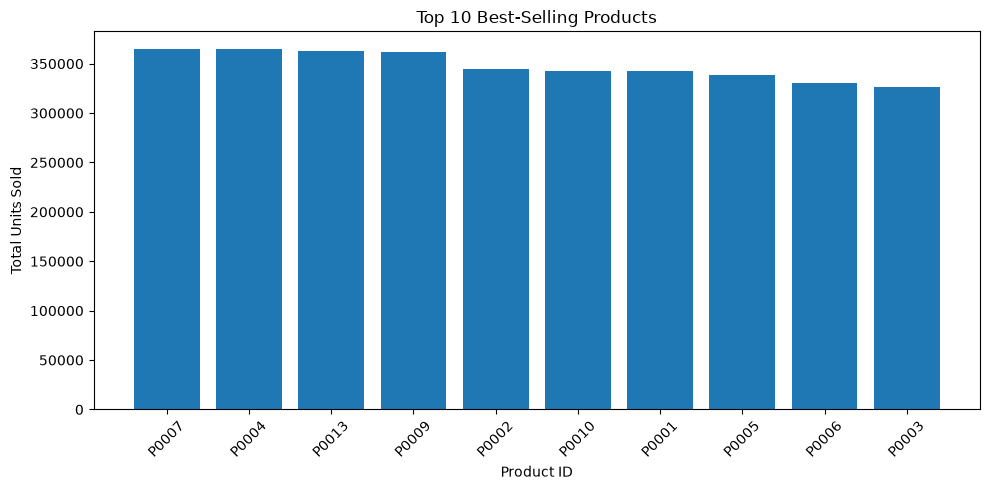

In [397]:


# Select the top 10 products
top_10 = product_sales.head(10)

# Create the bar chart
plt.figure(figsize=(10, 5))
plt.bar(
    top_10["Product ID"],
    top_10["Total_Units_Sold"]
)

# Add chart labels and title
plt.title("Top 10 Best-Selling Products")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()


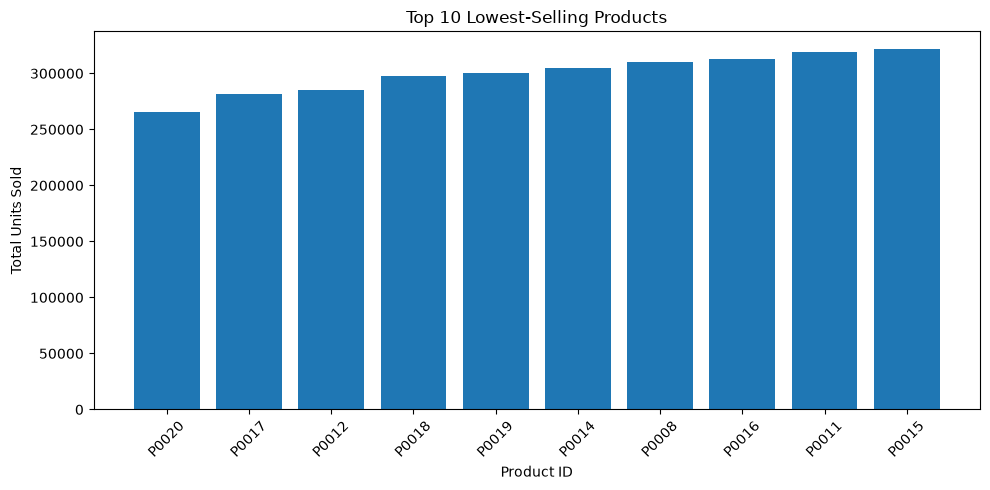

In [398]:

# Select the bottom 10 products
bottom_10 = product_sales.sort_values(
    by="Total_Units_Sold",
    ascending=True
).head(10)

# Create the bar chart
plt.figure(figsize=(10, 5))
plt.bar(
    bottom_10["Product ID"],
    bottom_10["Total_Units_Sold"]
)

# Add chart labels and title
plt.title("Top 10 Lowest-Selling Products")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()


In [399]:

# Extract year and month from Date
df["YearMonth"] = df["Date"].dt.to_period("M")

# Calculate total monthly sales
monthly_sales = df.groupby("YearMonth")["Units Sold"].sum()

# Display monthly sales
print(monthly_sales)


YearMonth
2022-01      8592
2022-02    271108
2022-03    303752
2022-04    260812
2022-05    205949
2022-06    292816
2022-07    220157
2022-08    316705
2022-09    277151
2022-10    280227
2022-11    276788
2022-12    296772
2023-01    288551
2023-02    173247
2023-03    296491
2023-04    216166
2023-05    252560
2023-06    303010
2023-07    313395
2023-08    315862
2023-09    276006
2023-10    225274
2023-11    274574
2023-12    280090
2024-01    249918
Freq: M, Name: Units Sold, dtype: int64


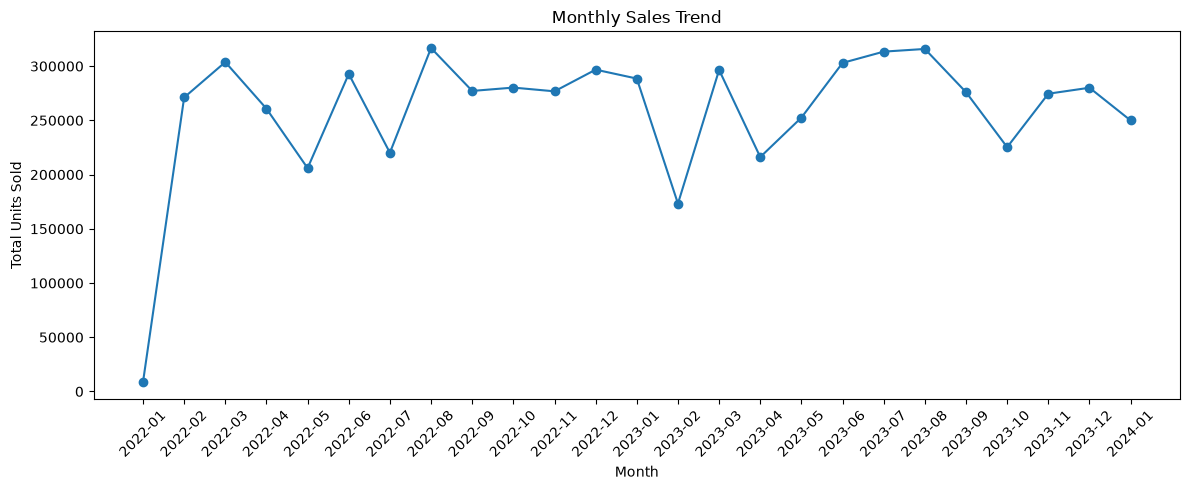

In [400]:


# Create the line chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

# Add title and labels
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")

# Rotate month labels
plt.xticks(rotation=45)

# Display chart
plt.tight_layout()
plt.show()


In [401]:

# Remove the first and last partial months
monthly_sales_complete = monthly_sales.iloc[1:-1]

# Display complete-month sales
print(monthly_sales_complete)


YearMonth
2022-02    271108
2022-03    303752
2022-04    260812
2022-05    205949
2022-06    292816
2022-07    220157
2022-08    316705
2022-09    277151
2022-10    280227
2022-11    276788
2022-12    296772
2023-01    288551
2023-02    173247
2023-03    296491
2023-04    216166
2023-05    252560
2023-06    303010
2023-07    313395
2023-08    315862
2023-09    276006
2023-10    225274
2023-11    274574
2023-12    280090
Freq: M, Name: Units Sold, dtype: int64


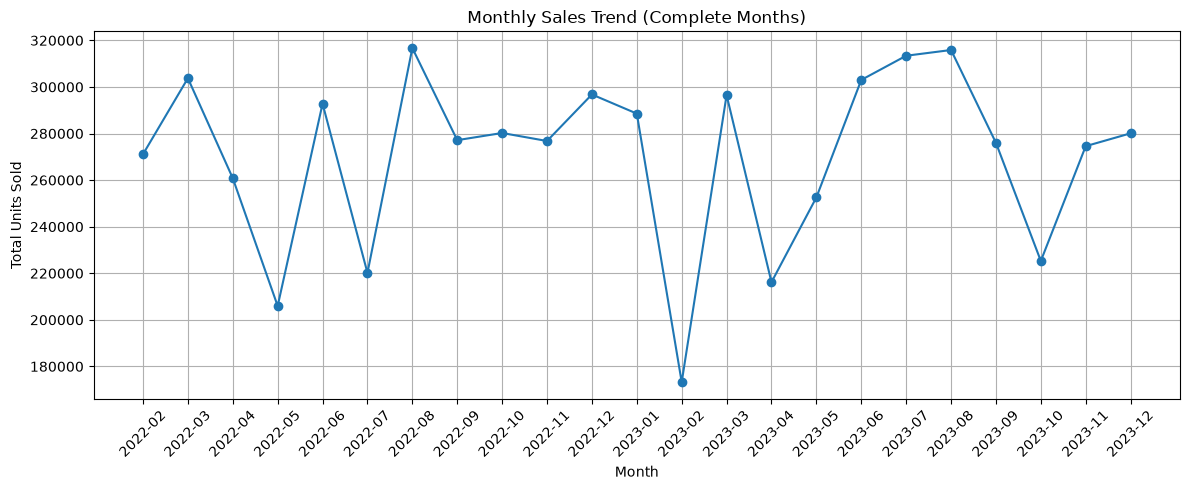

In [402]:


plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales_complete.index.astype(str),
    monthly_sales_complete.values,
    marker="o"
)

plt.title("Monthly Sales Trend (Complete Months)")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


In [403]:
category_columns = [
    col for col in df.columns
    if col.startswith("Category_")
]

if category_columns:
    df["Category"] = (
        df[category_columns]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0)
        .idxmax(axis=1)
        .str.replace("Category_", "", regex=False)
    )

    df.loc[
        df[category_columns].sum(axis=1) == 0,
        "Category"
    ] = "Unknown"

elif "Category" not in df.columns:
    raise ValueError("No category columns found in df.")

print(df["Category"].value_counts())

category_sales = df.groupby("Category").agg(
    Total_Units_Sold=("Units Sold", "sum")
).reset_index()

print(category_sales)

Category
Groceries      29200
Furniture      13140
Clothing       11680
Toys           10220
Electronics     8760
Name: count, dtype: int64
      Category  Total_Units_Sold
0     Clothing           1100905
1  Electronics            726855
2    Furniture            843418
3    Groceries           3006578
4         Toys            798217


In [404]:

# Calculate sales for each product category

category_sales = df.groupby("Category").agg(
    Total_Units_Sold=("Units Sold", "sum"),
    Average_Units_Sold=("Units Sold", "mean"),
    Total_Demand=("Demand", "sum"),
    Average_Demand=("Demand", "mean")
).reset_index()

# Sort categories by total units sold
category_sales = category_sales.sort_values(
    by="Total_Units_Sold",
    ascending=False
)

# Display the results
print(category_sales)


      Category  Total_Units_Sold  Average_Units_Sold  Total_Demand  \
3    Groceries           3006578          102.965000       3531575   
0     Clothing           1100905           94.255565       1308750   
2    Furniture            843418           64.187062        962963   
4         Toys            798217           78.103425        941623   
1  Electronics            726855           82.974315        851677   

   Average_Demand  
3      120.944349  
0      112.050514  
2       73.284855  
4       92.135323  
1       97.223402  


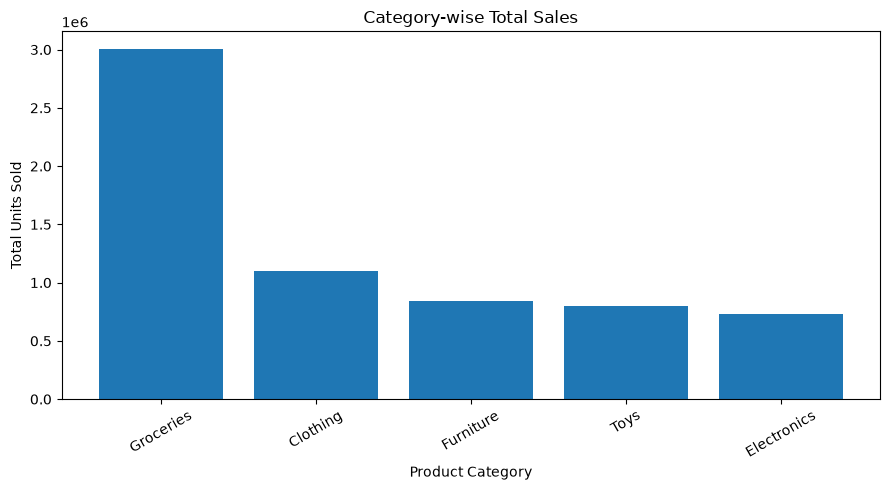

In [405]:

#category wise graph
plt.figure(figsize=(9, 5))

plt.bar(
    category_sales["Category"],
    category_sales["Total_Units_Sold"]
)

plt.title("Category-wise Total Sales")
plt.xlabel("Product Category")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [406]:

# Compare sales with and without promotions

promotion_sales = df.groupby("Promotion").agg(
    Average_Units_Sold=("Units Sold", "mean"),
    Total_Units_Sold=("Units Sold", "sum"),
    Average_Demand=("Demand", "mean")
).reset_index()

print(promotion_sales)


   Promotion  Average_Units_Sold  Total_Units_Sold  Average_Demand
0          0           81.740449           4005282       94.820918
1          1          102.945458           2470691      122.931792


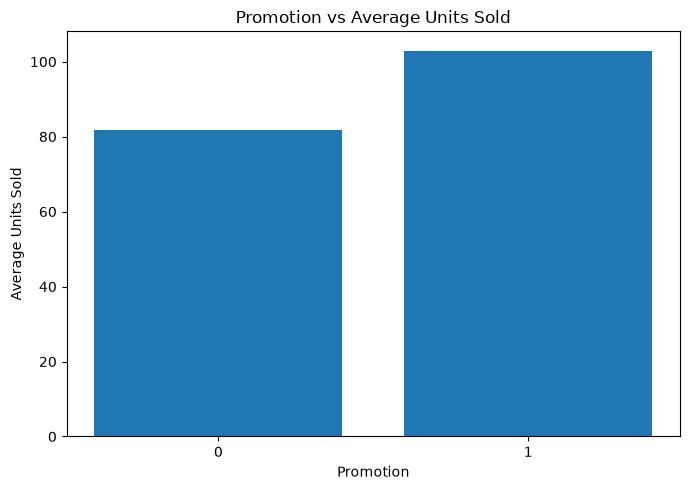

In [407]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    promotion_sales["Promotion"].astype(str),
    promotion_sales["Average_Units_Sold"]
)

plt.title("Promotion vs Average Units Sold")
plt.xlabel("Promotion")
plt.ylabel("Average Units Sold")

plt.tight_layout()
plt.show()


In [408]:

# Count records in each promotion group

promotion_counts = df["Promotion"].value_counts().sort_index()

print("Number of records:")
print(promotion_counts)


Number of records:
Promotion
0    49000
1    24000
Name: count, dtype: int64


In [409]:

# Select important numerical columns

correlation_columns = [
    "Units Sold",
    "Demand",
    "Units Ordered",
    "Inventory Level",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Promotion",
    "Epidemic"
]

# Calculate correlation
correlation_matrix = df[correlation_columns].corr()

# Display correlation values
print(correlation_matrix["Demand"].sort_values(ascending=False))


Demand                1.000000
Units Sold            0.836756
Units Ordered         0.512482
Promotion             0.280370
Discount              0.222727
Inventory Level       0.129896
Competitor Pricing   -0.022727
Price                -0.023215
Epidemic             -0.369135
Name: Demand, dtype: float64


In [410]:

# Columns to remove from model inputs
columns_to_remove = [
    "Demand_Next_7_Days",
    "Demand",
    "Units Sold",
    "Units Ordered",
    "Inventory Level",
    "Date",
    "Store ID",
    "Product ID",
    "Group_Row"
]

# Create input features
X = df_weekly.drop(columns=columns_to_remove)

# Create target variable
y = df_weekly["Demand_Next_7_Days"]

# Check dataset dimensions
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Check missing values
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())


Features Shape: (10400, 23)
Target Shape: (10400,)
Missing values in X: 0
Missing values in y: 0


In [411]:

# Sort weekly data by forecast date
df_weekly = df_weekly.sort_values(
    "Date"
).copy()

# Get unique forecast dates
unique_dates = sorted(df_weekly["Date"].unique())

# Calculate the 80% cutoff
split_index = int(len(unique_dates) * 0.8)

# Find the date separating training and testing
split_date = unique_dates[split_index]

print("Total unique forecast dates:", len(unique_dates))
print("Training ends before:", split_date)
print("Testing starts from:", split_date)


Total unique forecast dates: 104
Training ends before: 2023-09-04 00:00:00
Testing starts from: 2023-09-04 00:00:00


In [428]:
train_df = df_weekly[
    df_weekly["Date"] < split_date
].copy()

test_df = df_weekly[
    df_weekly["Date"] >= split_date
].copy()

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

print("Training date range:",
      train_df["Date"].min(), "to", train_df["Date"].max())

print("Testing date range:",
      test_df["Date"].min(), "to", test_df["Date"].max())

Training dataset: (8300, 32)
Testing dataset: (2100, 32)
Training date range: 2022-01-31 00:00:00 to 2023-08-28 00:00:00
Testing date range: 2023-09-04 00:00:00 to 2024-01-22 00:00:00


In [462]:
print("Text columns in X_train:")
print(X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist())

print("Text columns in X_test:")
print(X_test.select_dtypes(include=["object", "category", "string"]).columns.tolist())
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Text columns in X_train:
[]
Text columns in X_test:
[]
Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0


In [479]:
from sklearn.model_selection import cross_validate
import pandas as pd

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error"
}

cv_rows = []

for name, model in models.items():
    print(f"Evaluating {name}...")

    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv_folds,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_rows.append({
        "Model": name,
        "CV_MAE": -results["test_MAE"].mean(),
        "CV_RMSE": -results["test_RMSE"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV_MAE")

print(cv_results.round(3))

Evaluating Ridge...
Evaluating RandomForest...
Evaluating XGBoost...
Evaluating LightGBM...
          Model   CV_MAE  CV_RMSE
1  RandomForest  113.690  150.941
3      LightGBM  115.283  149.671
0         Ridge  117.489  151.968
2       XGBoost  133.402  170.414


In [480]:
import numpy as np

df_weekly = df_weekly.reset_index(drop=True)
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

unique_dates = np.sort(df_weekly["Date"].unique())

split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_mask = df_weekly["Date"] < split_date
test_mask = df_weekly["Date"] >= split_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Split date:", split_date)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("Training date range:",
      df_weekly.loc[train_mask, "Date"].min(),
      "to",
      df_weekly.loc[train_mask, "Date"].max())

print("Testing date range:",
      df_weekly.loc[test_mask, "Date"].min(),
      "to",
      df_weekly.loc[test_mask, "Date"].max())

Split date: 2023-09-04T00:00:00.000000
Training features: (8300, 23)
Testing features: (2100, 23)
Training target: (8300,)
Testing target: (2100,)
Training date range: 2022-01-31 00:00:00 to 2023-08-28 00:00:00
Testing date range: 2023-09-04 00:00:00 to 2024-01-22 00:00:00


In [481]:

print("Training Start:", train_df["Date"].min())
print("Training End:", train_df["Date"].max())

print("Testing Start:", test_df["Date"].min())
print("Testing End:", test_df["Date"].max())

# Verify chronological separation
print(
    "Training ends before testing:",
    train_df["Date"].max() < test_df["Date"].min()
)


Training Start: 2022-01-31 00:00:00
Training End: 2023-08-28 00:00:00
Testing Start: 2023-09-04 00:00:00
Testing End: 2024-01-22 00:00:00
Training ends before testing: True


In [482]:

print("Weekly Dataset:", df_weekly.shape)
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nMissing values:")
print("X_train:", X_train.isnull().sum().sum())
print("X_test:", X_test.isnull().sum().sum())
print("y_train:", y_train.isnull().sum())
print("y_test:", y_test.isnull().sum())


Weekly Dataset: (10400, 32)
Training Features: (8300, 23)
Testing Features: (2100, 23)
Training Target: (8300,)
Testing Target: (2100,)

Missing values:
X_train: 0
X_test: 0
y_train: 0
y_test: 0


In [483]:
%pip install  shap xgboost lightgbm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap # type: ignore

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor # type: ignore
from lightgbm import LGBMRegressor # type: ignore

assert 'X_train' in globals(), 'Run the feature creation notebook first'
drop_cols = ['Year', 'DayOfWeek', 'IsWeekend']
X_train = X_train.drop(columns=drop_cols, errors='ignore')
X_test = X_test.drop(columns=drop_cols, errors='ignore')
print(X_train.shape, X_test.shape)

Note: you may need to restart the kernel to use updated packages.
(8300, 20) (2100, 20)



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [484]:
def scores(y_true, y_pred):
    y_true = np.asarray(y_true)
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'WAPE_%': 100 * np.abs(y_true - y_pred).sum() / np.abs(y_true).sum(),
        'R2': r2_score(y_true, y_pred),
    }

train_dates = train_df['Date'].values
uniq = np.sort(np.unique(train_dates))
n = len(uniq)
bounds = [int(n * p) for p in (0.55, 0.70, 0.85)]

folds = []
for i, b in enumerate(bounds):
    tr = np.where(train_dates < uniq[b - 1])[0]
    if i + 1 < len(bounds):
        va = np.where((train_dates >= uniq[b]) & (train_dates < uniq[bounds[i + 1]]))[0]
    else:
        va = np.where(train_dates >= uniq[b])[0]
    folds.append((tr, va))
    print('fold', i + 1, 'train rows', len(tr), 'val rows', len(va))

fold 1 train rows 4400 val rows 1300
fold 2 train rows 5700 val rows 1200
fold 3 train rows 6900 val rows 1300


In [485]:
naive_test = 7 * X_test['Demand_Rolling_Mean_7']
naive_scores = scores(y_test, naive_test)
print('Naive baseline on test:', {k: round(v, 3) for k, v in naive_scores.items()})

naive_cv_mae = np.mean([
    mean_absolute_error(y_train.iloc[va], 7 * X_train['Demand_Rolling_Mean_7'].iloc[va])
    for _, va in folds
])
print('Naive baseline CV MAE:', round(naive_cv_mae, 3))

Naive baseline on test: {'MAE': 148.438, 'RMSE': 192.796, 'WAPE_%': 20.142, 'R2': 0.286}
Naive baseline CV MAE: 133.848


In [486]:
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

target = "Demand_Next_7_Days"

X_train = train_df.drop(
    columns=[target, "Date", "Demand", "Group_Row"],
    errors="ignore"
).copy()

X_test = test_df.drop(
    columns=[target, "Date", "Demand", "Group_Row"],
    errors="ignore"
).copy()

y_train = pd.to_numeric(train_df[target], errors="coerce")
y_test = pd.to_numeric(test_df[target], errors="coerce")

X_train = X_train.loc[:, ~X_train.columns.duplicated()]
X_test = X_test.loc[:, ~X_test.columns.duplicated()]

X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)

X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

X_train = X_train.apply(pd.to_numeric, errors="coerce")
X_test = X_test.apply(pd.to_numeric, errors="coerce")

X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

valid_train = y_train.notna()
valid_test = y_test.notna()

X_train = X_train.loc[valid_train].reset_index(drop=True)
y_train = y_train.loc[valid_train].reset_index(drop=True)

X_test = X_test.loc[valid_test].reset_index(drop=True)
y_test = y_test.loc[valid_test].reset_index(drop=True)

cv_folds = TimeSeriesSplit(n_splits=3)

models = {
    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "RandomForest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        n_jobs=1,
        random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=1
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=400,
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=30,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbosity=-1,
        n_jobs=1
    )
}

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Remaining text columns:",
      X_train.select_dtypes(include=["object", "category"]).columns.tolist())

Training shape: (8300, 64)
Testing shape: (2100, 64)
Remaining text columns: []


In [487]:
import pandas as pd

X_train = X_train.copy()
X_test = X_test.copy()

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

X_train = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    dtype=int
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_train = X_train.loc[:, ~X_train.columns.duplicated()].copy()
X_test = X_test.loc[:, ~X_test.columns.duplicated()].copy()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Remaining text columns:", X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist())

Training shape: (8300, 64)
Testing shape: (2100, 64)
Remaining text columns: []


In [488]:
duplicate_columns = df.columns[
    df.columns.duplicated()
].unique().tolist()

print("Duplicate columns:", duplicate_columns)

columns_with_different_values = []

for col in duplicate_columns:
    matching_cols = df.loc[:, df.columns == col]
    first_column = matching_cols.iloc[:, 0]

    identical = all(
        first_column.equals(matching_cols.iloc[:, i])
        for i in range(1, matching_cols.shape[1])
    )

    print(f"{col}: {identical}")

    if not identical:
        columns_with_different_values.append(col)

if not columns_with_different_values:
    df = df.loc[:, ~df.columns.duplicated()].copy()
    print("Duplicate columns removed successfully.")
else:
    print("Different values found in:", columns_with_different_values)
    print("No columns removed.")

print("Final shape:", df.shape)
print("Remaining duplicates:", df.columns[df.columns.duplicated()].tolist())

Duplicate columns: []
Duplicate columns removed successfully.
Final shape: (73000, 33)
Remaining duplicates: []


In [489]:
param_dist = {
    'n_estimators': [200, 400, 600, 800],
    'learning_rate': [0.02, 0.03, 0.05, 0.08],
    'num_leaves': [7, 15, 31, 63],
    'min_child_samples': [10, 20, 40, 80],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0, 0.1, 1, 5],
    'reg_lambda': [0, 1, 5, 10],
}

search = RandomizedSearchCV(
    LGBMRegressor(subsample_freq=1, random_state=42, verbose=-1),
    param_distributions=param_dist,
    n_iter=30,
    cv=folds,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=1,
)
search.fit(X_train, y_train)

print('Best params:', search.best_params_)
print('Best CV MAE:', round(-search.best_score_, 3))

best_model = search.best_estimator_
best_pred = best_model.predict(X_test)
print('Tuned LightGBM on test:', {k: round(v, 3) for k, v in scores(y_test, best_pred).items()})

Best params: {'subsample': 0.9, 'reg_lambda': 5, 'reg_alpha': 5, 'num_leaves': 7, 'n_estimators': 200, 'min_child_samples': 20, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV MAE: 106.701
Tuned LightGBM on test: {'MAE': 111.886, 'RMSE': 149.864, 'WAPE_%': 15.962, 'R2': 0.42}


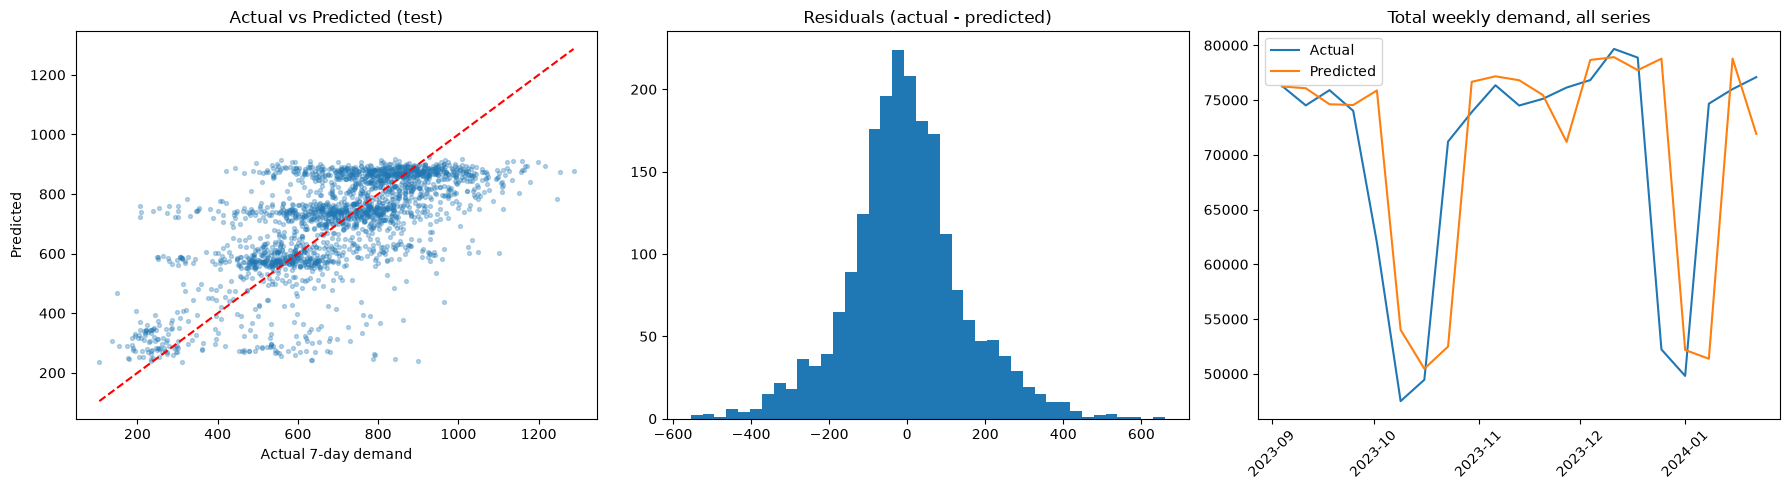

In [490]:
resid = y_test.values - best_pred

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].scatter(y_test, best_pred, alpha=0.3, s=8)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, 'r--')
ax[0].set_title('Actual vs Predicted (test)')
ax[0].set_xlabel('Actual 7-day demand')
ax[0].set_ylabel('Predicted')

ax[1].hist(resid, bins=40)
ax[1].set_title('Residuals (actual - predicted)')

by_date = pd.DataFrame({'Date': test_df['Date'].values, 'actual': y_test.values, 'pred': best_pred})
by_date = by_date.groupby('Date').sum()
ax[2].plot(by_date.index, by_date['actual'], label='Actual')
ax[2].plot(by_date.index, by_date['pred'], label='Predicted')
ax[2].set_title('Total weekly demand, all series')
ax[2].legend()
ax[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

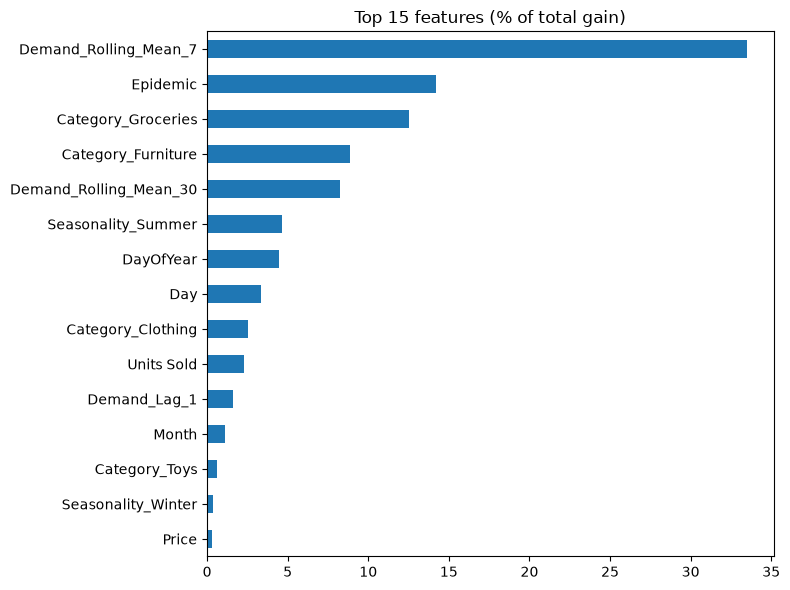

Demand_Rolling_Mean_7     33.47
Epidemic                  14.22
Category_Groceries        12.53
Category_Furniture         8.85
Demand_Rolling_Mean_30     8.27
Seasonality_Summer         4.67
DayOfYear                  4.48
Day                        3.36
Category_Clothing          2.54
Units Sold                 2.31
Demand_Lag_1               1.63
Month                      1.12
Category_Toys              0.61
Seasonality_Winter         0.36
Price                      0.31
dtype: float64

In [491]:
imp = pd.Series(
    best_model.booster_.feature_importance(importance_type='gain'),
    index=X_train.columns,
).sort_values(ascending=False)
imp = 100 * imp / imp.sum()

imp.head(15).iloc[::-1].plot(kind='barh', figsize=(8, 6))
plt.title('Top 15 features (% of total gain)')
plt.tight_layout()
plt.show()
imp.head(15).round(2)

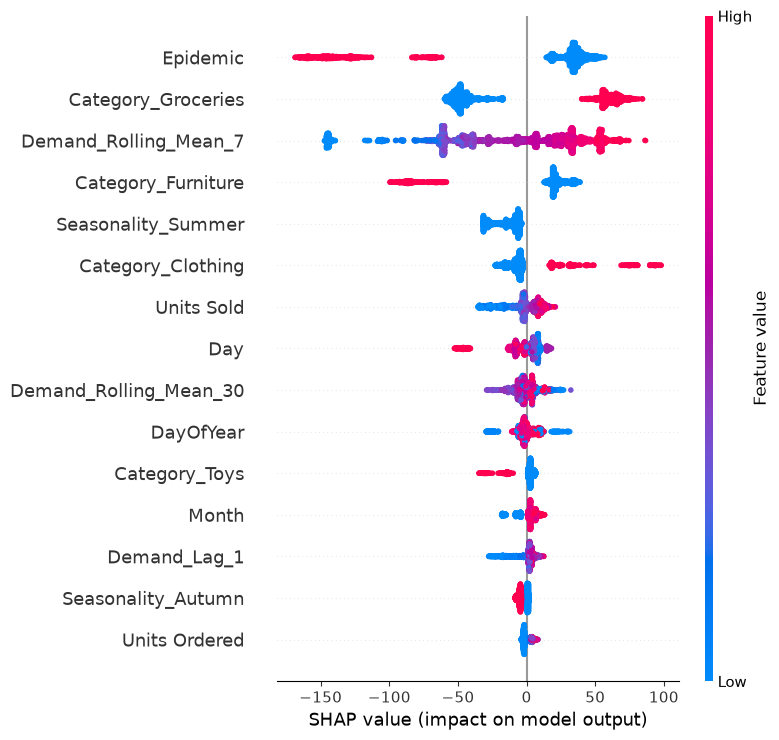

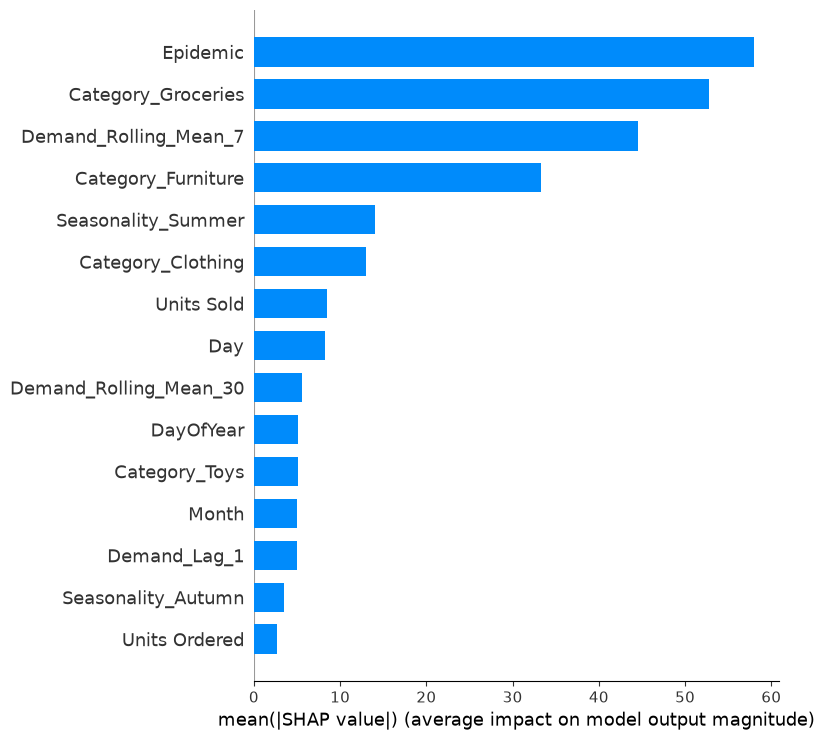

In [492]:
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, max_display=15)
shap.summary_plot(shap_values, X_test, plot_type='bar', max_display=15)

In [493]:
i = 0
print('Actual:', y_test.iloc[i], ' Predicted:', round(best_pred[i], 1), ' Base value:', round(float(explainer.expected_value), 1))
contrib = pd.Series(shap_values[i], index=X_test.columns).sort_values(key=np.abs, ascending=False)
contrib.head(10).round(2)

Actual: 739.0  Predicted: 868.5  Base value: 735.4


Category_Groceries        57.05
Epidemic                  34.38
Seasonality_Summer       -30.26
Demand_Rolling_Mean_7     26.08
Category_Furniture        20.89
Product ID_P0002           9.34
Day                        8.82
Units Sold                 7.27
Seasonality_Autumn        -5.05
Demand_Rolling_Mean_30     4.78
dtype: float64

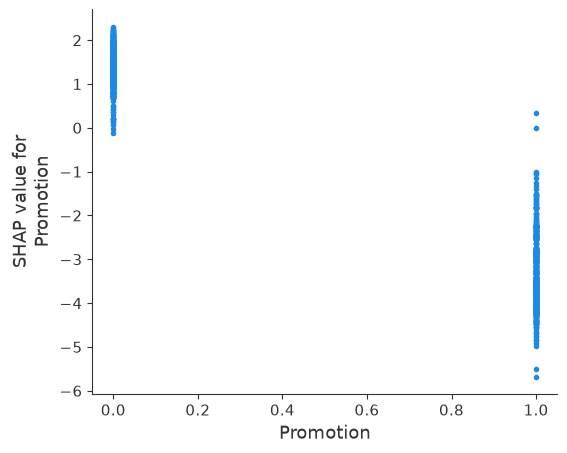

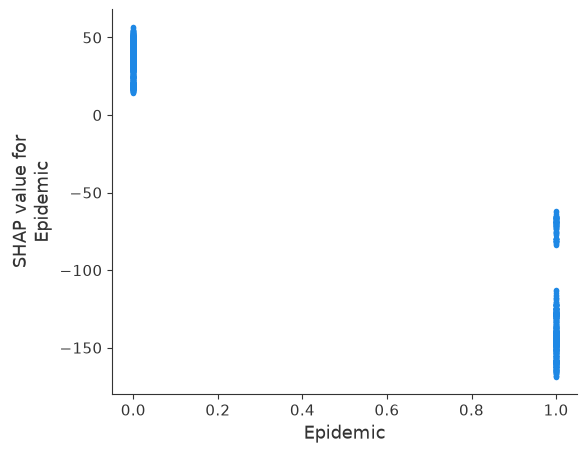

In [494]:
for f in ['Promotion', 'Epidemic']:
    shap.dependence_plot(f, shap_values, X_test, interaction_index=None)

In [496]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_model_name = cv_results.iloc[0]["Model"]
best_model = clone(models[best_model_name])

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Best Model:", best_model_name)
print("Test MAE:", round(mae, 3))
print("Test RMSE:", round(rmse, 3))
print("Test R2 Score:", round(r2, 3))

Best Model: RandomForest
Test MAE: 112.855
Test RMSE: 151.282
Test R2 Score: 0.409


In [498]:
absolute_errors = np.abs(np.array(y_test) - np.array(y_pred))

wape = (
    absolute_errors.sum() / np.abs(np.array(y_test)).sum()
) * 100

print("WAPE:", round(wape, 2), "%")

WAPE: 16.1 %


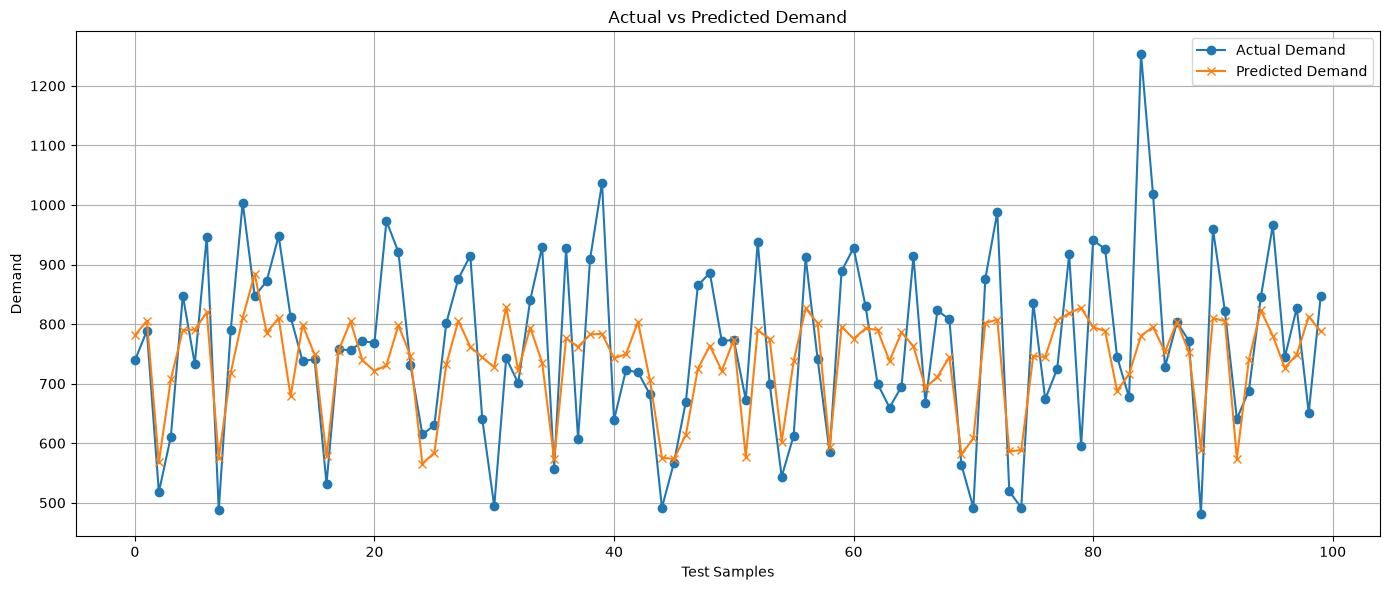

In [502]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 6))

plt.plot(
    np.array(y_test)[:100],
    label="Actual Demand",
    marker="o"
)

plt.plot(
    np.array(y_pred)[:100],
    label="Predicted Demand",
    marker="x"
)

plt.title("Actual vs Predicted Demand")
plt.xlabel("Test Samples")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

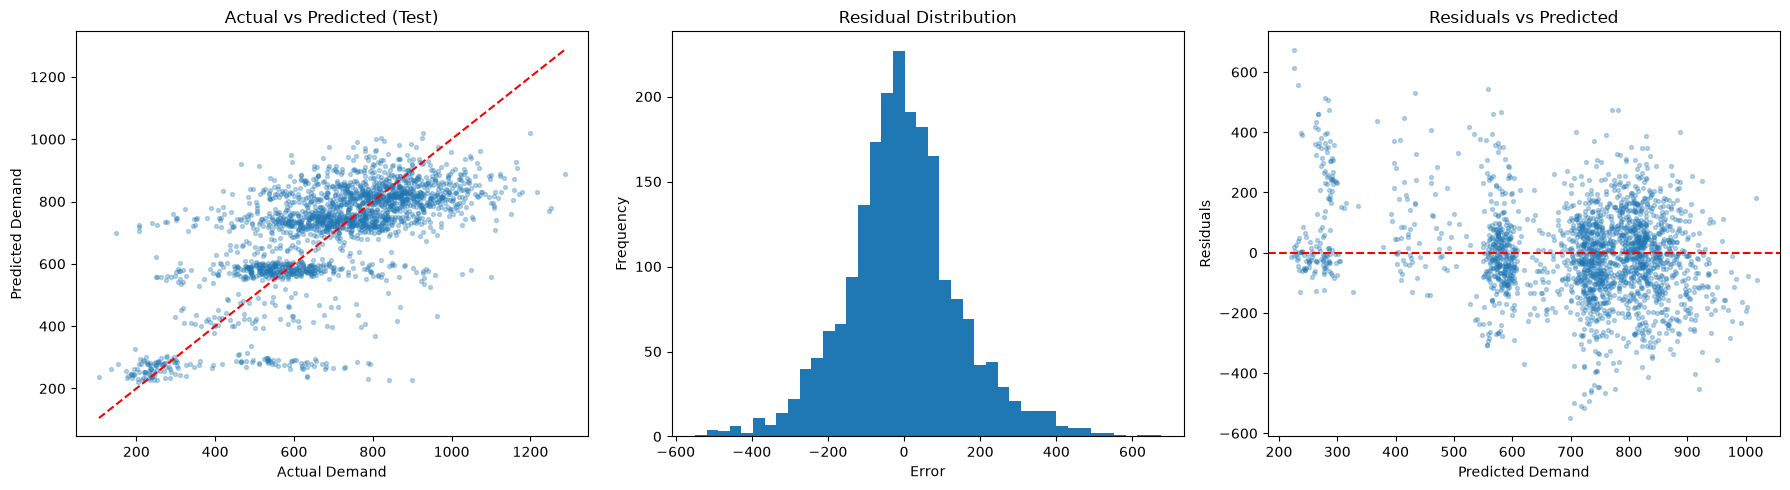

In [504]:
resid = np.array(y_test) - np.array(y_pred)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].scatter(y_test, y_pred, alpha=0.3, s=8)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lims, lims, 'r--')
ax[0].set_title('Actual vs Predicted (Test)')
ax[0].set_xlabel('Actual Demand')
ax[0].set_ylabel('Predicted Demand')

ax[1].hist(resid, bins=40)
ax[1].set_title('Residual Distribution')
ax[1].set_xlabel('Error')
ax[1].set_ylabel('Frequency')

ax[2].scatter(y_pred, resid, alpha=0.3, s=8)
ax[2].axhline(0, color='red', linestyle='--')
ax[2].set_title('Residuals vs Predicted')
ax[2].set_xlabel('Predicted Demand')
ax[2].set_ylabel('Residuals')

plt.tight_layout()
plt.show()

In [505]:
def wape_by(group):
    d = pd.DataFrame({'g': group.values, 'abs_err': np.abs(resid), 'actual': y_test.values})
    out = d.groupby('g').agg(abs_err=('abs_err', 'sum'), actual=('actual', 'sum'), rows=('g', 'size'))
    out['WAPE_%'] = 100 * out['abs_err'] / out['actual']
    return out[['rows', 'WAPE_%']].round(2)

cat_cols = [c for c in X_test.columns if c.startswith('Category_')]
reg_cols = [c for c in X_test.columns if c.startswith('Region_')]

print('By category'); display(wape_by(X_test[cat_cols].idxmax(axis=1)))
print('By region'); display(wape_by(X_test[reg_cols].idxmax(axis=1)))
print('By promotion'); display(wape_by(X_test['Promotion']))
print('By epidemic'); display(wape_by(X_test['Epidemic']))

By category


,rows,WAPE_%
g,,
Category_Clothing,336,12.35
Category_Electronics,252,17.10
Category_Furniture,378,17.79
Category_Groceries,840,14.91
Category_Toys,294,23.50


By region


,rows,WAPE_%
g,,
Region_East,420,16.59
Region_North,840,16.60
Region_South,420,15.78
Region_West,420,14.91


By promotion


,rows,WAPE_%
g,,
0,1435,15.75
1,665,16.87


By epidemic


,rows,WAPE_%
g,,
0,1600,14.22
1,500,23.66
